# Soil carbon and fire-weather transformers

Run `data_harmonization.ipynb` to prepare the input tables.

Run All loads the included weights and makes predictions. To train, uncomment the training cells.

Soil model source: `tangarine_USE_THIS_VERSION_Hawaii_Soils_Transformer.ipynb`.

| | Soil carbon | Fire weather |
|---|---|---|
| History | 36 records, spaced 30 days apart | 120 six-hour records |
| Inputs | Remote sensing, climate, terrain and season; carbon excluded | Weather, fire-size frequencies and time |
| Output | Next record, including carbon | Next 12 records of weather, fire-size frequencies and time |
| Readout | Last encoder timestep | Separate attention pooling for three output heads |
| Loss | MSE | Weather MSE + fire KL divergence + time MSE |

## Setup

Install `requirements.txt`. Open the notebook from the folder containing `data/` and `models/`. CPU execution is supported.

In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / "data").is_dir(), "Open the notebook from the handoff directory."
torch.set_num_threads(2)
torch.manual_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True})
print("PyTorch:", torch.__version__, "| device:", torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else DEVICE)

PyTorch: 2.13.0+rocm10.0.0 | device: AMD Radeon 8060S Graphics


## Soil carbon

The harmonization notebook aligns Landsat bands, filters and smooths observations, creates 30-day records, and joins climate, terrain and carbon data. The inputs come from real observations with locations obscured and values slightly perturbed.

In [2]:
bands = ['doy_sin', 'doy_cos',
         'Blue', 'Green', 'Red', 'NIR', 'SWIR-1', 'SWIR-2',
         'aet', 'def','pdsi', 'pet', 'pr', 'ro', 'soil', 'srad', 'swe', 'tmmn', 'tmmx', 'vap','vpd', 'vs',
         'SRTM', 'slope', 'elevation','aspect_sin', 'aspect_cos',
         'imp_c']

# Load the prepared sample.
all_data = pd.read_csv(ROOT / "data/soil_carbon_harmonized.csv", parse_dates=["date"])
all_data = all_data.rename(columns={"site_id": "unique_id"})
all_data = all_data.sort_values(["unique_id", "date"]).reset_index(drop=True)
all_data["doy_sin"] = np.sin(all_data.date.dt.dayofyear / 365)
all_data["doy_cos"] = np.cos(all_data.date.dt.dayofyear / 365)
assert np.isfinite(all_data[bands].to_numpy()).all()
print(f"{all_data.unique_id.nunique()} obscured sites, {len(all_data)} records")
display(all_data[["unique_id", "date", "Blue", "NIR", "pr", "imp_c"]].head())

4 obscured sites, 536 records


,unique_id,date,Blue,NIR,pr,imp_c
0,site_01,2014-01-16,8423.352866,11326.877274,80.68050,1.3565
1,site_01,2014-02-15,8418.004221,11352.192974,82.41876,1.3565
2,site_01,2014-03-17,8419.016963,11384.376435,72.13916,1.3565
3,site_01,2014-04-16,8488.457995,11497.975378,17.71377,1.3565
4,site_01,2014-05-16,8649.656294,11701.718399,113.36092,1.3565


In [3]:
SEQ_LENGTH = 12*3

def create_sequences(data, input_target_col, output_target_col, seq_length):
    sequences = []
    targets = []
    ids = []
    for loc, group in data.groupby(['unique_id']):
        input_values = group[input_target_col].values

        output_values = group[output_target_col].values

        id = group['unique_id'].values
        for i in range(len(input_values) - seq_length):
            sequences.append(input_values[i:i + seq_length])
            targets.append(output_values[i + seq_length])
            ids.append(id[i + seq_length])
    return np.array(sequences), np.array(targets), np.array(ids)

class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Load the normalization saved with the weights.
soil_norm = json.loads((ROOT / "models/soil_normalization.json").read_text())
test_sample_df = all_data.copy()
for band in bands:
    test_sample_df[band] = test_sample_df[band].astype(float)
    test_sample_df[band] = (test_sample_df[band] - soil_norm[band]['mean']) / soil_norm[band]['std']
X_test, y_test, ids = create_sequences(test_sample_df, bands, bands, SEQ_LENGTH)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)
test_dataset = TimeSeriesDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
# Dates are display metadata, not model inputs outside the listed bands.
soil_dates = np.concatenate([
    group.date.iloc[SEQ_LENGTH:].to_numpy()
    for _, group in test_sample_df.groupby(['unique_id'])
])
print("Soil input:", X_test.shape, "| next-record target:", y_test.shape)

Soil input: (392, 36, 28) | next-record target: (392, 28)


### Model

The class below is copied from `tangarine_USE_THIS_VERSION_Hawaii_Soils_Transformer.ipynb`. It excludes carbon from the input embedding and copies static terrain values to the output.

In [4]:
class TimeSeriesTransformer(nn.Module):
    def __init__(self, seq_length, input_dim=6, output_dim=7,
                 model_dim=256, num_heads=8, num_layers=6,
                 dropout=0.1, static_indices=None, training_indices=None):
        super(TimeSeriesTransformer, self).__init__()
        self.input_dim = input_dim
        self.static_indices = static_indices or []
        self.training_indices = training_indices or []

        # determine which input channels the model actually sees
        self.embed_indices = [i for i in range(input_dim) if i not in self.training_indices]

        # embedding only for non-training channels
        self.embedding = nn.Linear(len(self.embed_indices), model_dim)

        self.encoder_layer = nn.TransformerEncoderLayer(d_model=model_dim, nhead=num_heads, dropout=dropout)
        self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(model_dim, output_dim)

    def forward(self, x):
        x_in = x  # keep full inputs

        # select & embed only non-training channels
        x_sel = x_in[:, :, self.embed_indices]                     # (batch, seq_length, len(embed_indices))
        x = self.embedding(x_sel)                                  # (batch, seq_length, model_dim)
        x = x.permute(1, 0, 2)                                      # (seq_length, batch, model_dim)
        x = self.transformer_encoder(x)
        x = x[-1]                                                   # (batch, model_dim)

        out = self.fc_out(x)                                        # (batch, output_dim)

        # copy over static covariates
        for idx in self.static_indices:
            out[:, idx] = x_in[:, -1, idx]

        return out

### Training

These cells use the source notebook's split, normalization, batch size, model settings, optimizer and training loop. Use the resulting `norm_params` with the model you train.

In [5]:
# unique_ids = all_data["unique_id"].unique()
#
# # Randomly shuffle the unique_ids
# np.random.shuffle(unique_ids)
#
# # Define split index (90% train, 10% test as per your comment, though the comment says 99% train, 1% test)
# split_idx = int(len(unique_ids) * 0.9)
#
#
# train_ids = unique_ids[:split_idx]
# test_ids = unique_ids[split_idx:]
#
#
# sample_df = all_data[all_data['unique_id'].isin(train_ids)]
#
# # # Normalize data
# # for l in bands_input + [band_output]:
# #   sample_df[l] = sample_df[l].astype(float)/65535 - 0.5
#
# # Compute normalization parameters
# epsilon = 1e-8
# norm_params = {}
# for band in bands:
#     sample_df[band] = sample_df[band].astype(float)
#     mean_val = sample_df[band].mean() + epsilon
#     std_val = sample_df[band].std() + epsilon
#     norm_params[band] = {'mean': mean_val, 'std': std_val}
#     # Normalize
#     sample_df[band] = (sample_df[band] - mean_val) / std_val
#
#
#
#
#
# X, y, ids = create_sequences(sample_df, bands, bands, SEQ_LENGTH)
#
# # Convert to PyTorch tensors
# X_tensor = torch.tensor(X, dtype=torch.float32)
# y_tensor = torch.tensor(y, dtype=torch.float32)
#
#
#
# # Initialize dataset
# dataset = TimeSeriesDataset(X_tensor, y_tensor)
#
# data_loader = DataLoader(dataset, batch_size=256*4, shuffle=True)
#
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#
# static_bands = ['SRTM', 'slope', 'elevation', 'aspect_sin', 'aspect_cos']
# static_indices   = [bands.index(b) for b in static_bands]
# # static_indices   = []
# training_indices = [bands.index('imp_c')]
#
# model = TimeSeriesTransformer(
#     seq_length=SEQ_LENGTH,
#     input_dim=len(bands),
#     output_dim=len(bands),
#     model_dim=128,
#     num_heads=8,
#     num_layers=8,
#     dropout=0.5,
#     static_indices=static_indices,
#     training_indices=training_indices
# ).to(device)
#
# # Define loss function & optimizer
# criterion = nn.MSELoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=0.00001)
#
# # Training loop
# EPOCHS = 40
# input_dim=len(bands)-1
# for epoch in range(EPOCHS):
#     model.train()
#     epoch_loss = 0
#     i = 0
#     for X_batch, y_batch in data_loader:
#         X_batch, y_batch = X_batch.to(device), y_batch.to(device)  # Move to GPU
#         X_batch = X_batch
#         # print(X_batch.shape)
#         # print(y_batch.shape)
#         optimizer.zero_grad()
#         output = model(X_batch)
#         loss = criterion(output.squeeze(), y_batch)
#         loss.backward()
#         optimizer.step()
#         epoch_loss += loss.item()
#         i += 1
#         # print(i)
#
#     print(f"Epoch {epoch+1}/{EPOCHS}, Loss: {epoch_loss / len(data_loader)}")

### Prediction

Load the saved weights and their normalization, then predict carbon in the original `imp_c` scale.

<ipython-input-16-79649ff577fb>:17: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=num_layers)


,obscured_carbon_label,predicted_carbon
site_id,,
site_01,1.356,-0.813
site_02,3.825,2.687
site_03,8.120,9.773
site_04,13.134,10.850


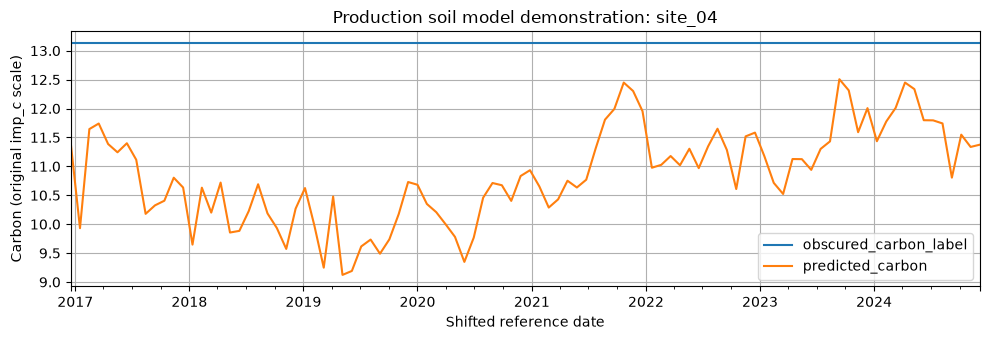

In [6]:
device = DEVICE

static_bands = ['SRTM', 'slope', 'elevation', 'aspect_sin', 'aspect_cos']
static_indices   = [bands.index(b) for b in static_bands]
# static_indices   = []
training_indices = [bands.index('imp_c')]

model = TimeSeriesTransformer(
    seq_length=SEQ_LENGTH,
    input_dim=len(bands),
    output_dim=len(bands),
    model_dim=128,
    num_heads=8,
    num_layers=8,
    dropout=0.5,
    static_indices=static_indices,
    training_indices=training_indices
).to(device)

model.load_state_dict(torch.load(ROOT / "models/soil_weights.pt", map_location=device, weights_only=True))


# Set model to evaluation mode
model.eval()

# Store predictions
all_predictions = []
all_reference = []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)  # Move to GPU
        # print(X_batch.shape)  # Should be (batch_size, seq_length, 7)

        batch_preds = model(X_batch)  # Get predictions (batch_size, 7)
        all_predictions.append(batch_preds.cpu())  # Move to CPU to avoid memory issues
        all_reference.append(y_batch.cpu())
# Concatenate all batches into a single array
predictions = torch.cat(all_predictions).numpy()  # Keep shape (num_samples, 7)
reference = torch.cat(all_reference).numpy()
reference.shape
# y_test = y_test_tensor.cpu().numpy()  # Ensure target shape (num_samples, 7)
# y_test

carbon_index = bands.index("imp_c")
carbon_mean = soil_norm["imp_c"]["mean"]
carbon_std = soil_norm["imp_c"]["std"]
soil_predictions = pd.DataFrame({
    "site_id": ids,
    "date": soil_dates,
    "obscured_carbon_label": reference[:, carbon_index] * carbon_std + carbon_mean,
    "predicted_carbon": predictions[:, carbon_index] * carbon_std + carbon_mean,
})
display(soil_predictions.groupby("site_id")[["obscured_carbon_label", "predicted_carbon"]].mean().round(3))
example = soil_predictions[soil_predictions.site_id == soil_predictions.site_id.iloc[-1]]
ax = example.plot(x="date", y=["obscured_carbon_label", "predicted_carbon"],
                  title=f"Production soil model demonstration: {example.site_id.iloc[0]}")
ax.set_ylabel("Carbon (original imp_c scale)")
ax.set_xlabel("Shifted reference date")
plt.tight_layout()
plt.show()

## Fire weather

The harmonization notebook combines real CFSv2 weather and daily fire-size distributions on six-hour timestamps. Each event includes 30 preceding weather days and eight days of fire observations.

In [7]:
def make_windows(frame, group_col, features, lookback, horizon, stride=1):
    """Keep each input/target pair inside one site or fire, in date order."""
    X, y, groups, dates = [], [], [], []
    for group_id, group in frame.groupby(group_col, sort=True):
        group = group.sort_values("date")
        values = group[features].to_numpy(dtype=np.float32)
        for end in range(lookback, len(group) - horizon + 1, stride):
            X.append(values[end-lookback:end])
            y.append(values[end:end+horizon])
            groups.append(group_id)
            dates.append(group.date.iloc[end:end+horizon].to_numpy())
    return np.stack(X), np.stack(y), np.array(groups), np.stack(dates)

fire_config = json.loads((ROOT / "models/fire_config.json").read_text())
WEATHER = fire_config["selected_feature_cols"]
FIRE_BINS = fire_config["fire_target_cols"]
TIME_FEATURES = fire_config["encoder_cols"]
FIRE_FEATURES = WEATHER + FIRE_BINS + TIME_FEATURES
BIN_EDGES = np.array([float(v) for v in fire_config["bin_edges"]])
fire = pd.read_csv(ROOT / "data/fire_harmonized.csv", parse_dates=["date"])
print(f"{fire.fire_id.nunique()} fires, {len(fire)} harmonized records")
display(fire[["fire_id", "date"] + FIRE_BINS].head())

3 fires, 456 harmonized records


,fire_id,date,bin_00,bin_01,bin_02,bin_03,bin_04
0,2002-NVHTF-001233,2002-05-16 00:00:00,0.0,0.0,0.0,0.0,0.0
1,2002-NVHTF-001233,2002-05-16 06:00:00,0.0,0.0,0.0,0.0,0.0
2,2002-NVHTF-001233,2002-05-16 12:00:00,0.0,0.0,0.0,0.0,0.0
3,2002-NVHTF-001233,2002-05-16 18:00:00,0.0,0.0,0.0,0.0,0.0
4,2002-NVHTF-001233,2002-05-17 00:00:00,0.0,0.0,0.0,0.0,0.0


In [8]:
def normalize_weather(frame, parameters):
    result = frame.copy()
    for name in WEATHER:
        low, high = parameters[name]["min"], parameters[name]["max"]
        result[name] = (result[name] - low) / (high - low) if high > low else 0.0
    return result

fire_norm = fire_config["minmax_params"]
fire_X, fire_y, fire_groups, fire_dates = make_windows(
    normalize_weather(fire, fire_norm), "fire_id", FIRE_FEATURES,
    lookback=120, horizon=12, stride=4  # one forecast origin per day
)
assert np.isfinite(fire_X).all() and np.isfinite(fire_y).all()
print("Fire input:", fire_X.shape, "| three-day target:", fire_y.shape)

Fire input: (18, 120, 34) | three-day target: (18, 12, 34)


### Model

Positional encoding is followed by a transformer encoder. Three learned queries pool the history for separate weather, fire and time outputs. The included checkpoint uses five diameter bins.

In [9]:
class PositionalEncoding(nn.Module):
    def __init__(self, model_dim, max_len):
        super().__init__()
        positions = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        scale = torch.exp(torch.arange(0, model_dim, 2) * (-math.log(10000.0) / model_dim))
        pe = torch.zeros(max_len, model_dim)
        pe[:, 0::2] = torch.sin(positions * scale)
        pe[:, 1::2] = torch.cos(positions * scale)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class FireTransformer(nn.Module):
    def __init__(self, seq_length, input_dim, n_weather, n_bins, n_time,
                 model_dim=256, num_heads=8, num_layers=6, dropout=0.1):
        super().__init__()
        self.embedding = nn.Linear(input_dim, model_dim)
        self.positional_encoding = PositionalEncoding(model_dim, seq_length)
        self.encoder_layer = nn.TransformerEncoderLayer(
            d_model=model_dim, nhead=num_heads, dropout=dropout, batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=num_layers)
        self.query_weather = nn.Parameter(torch.randn(model_dim))
        self.query_hist = nn.Parameter(torch.randn(model_dim))
        self.query_time = nn.Parameter(torch.randn(model_dim))
        self.head_weather = nn.Linear(model_dim, n_weather)
        self.head_hist = nn.Linear(model_dim, n_bins)
        self.head_time = nn.Linear(model_dim, n_time)

    def pool(self, encoded, query):
        scores = torch.matmul(encoded, query) / math.sqrt(encoded.size(-1))
        weights = torch.softmax(scores, dim=1)
        return (encoded * weights.unsqueeze(-1)).sum(dim=1)

    def forward(self, x):
        encoded = self.transformer_encoder(self.positional_encoding(self.embedding(x)))
        return torch.cat([
            self.head_weather(self.pool(encoded, self.query_weather)),
            self.head_hist(self.pool(encoded, self.query_hist)),
            self.head_time(self.pool(encoded, self.query_time)),
        ], dim=-1)


def split_fire_output(output):
    weather_out = output[:, :288].reshape(-1, 12, 24)
    fire_logits = output[:, 288:348].reshape(-1, 12, 5)
    time_out = output[:, 348:].reshape(-1, 12, 5)
    return weather_out, fire_logits, time_out

### Training

The loss combines weather MSE, fire-distribution KL divergence and time MSE. Fit weather normalization on the training data and retain it with the weights.

In [10]:
# fire_train = fire.copy()
# new_fire_norm = {
#     name: {"min": float(fire_train[name].min()), "max": float(fire_train[name].max())}
#     for name in WEATHER
# }
# train_X, train_y, _, _ = make_windows(
#     normalize_weather(fire_train, new_fire_norm), "fire_id", FIRE_FEATURES, 120, 12, stride=4
# )
# loader = DataLoader(TensorDataset(torch.from_numpy(train_X), torch.from_numpy(train_y)),
#                     batch_size=8, shuffle=True)
# new_fire_model = FireTransformer(**fire_config["model_config"]).to(DEVICE)
# optimizer = torch.optim.Adam(new_fire_model.parameters(), lr=1e-4)
# for epoch in range(100):
#     new_fire_model.train()
#     for X_batch, y_batch in loader:
#         X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
#         optimizer.zero_grad()
#         weather_out, fire_logits, time_out = split_fire_output(new_fire_model(X_batch))
#         weather_loss = F.mse_loss(weather_out, y_batch[:, :, :24])
#         fire_loss = F.kl_div(F.log_softmax(fire_logits.reshape(-1, 5), dim=-1),
#                              y_batch[:, :, 24:29].reshape(-1, 5), reduction="batchmean")
#         time_loss = F.mse_loss(time_out, y_batch[:, :, 29:])
#         loss = weather_loss + fire_loss + time_loss
#         loss.backward()
#         optimizer.step()
#     print(epoch + 1, float(loss.detach()))

### Prediction

Forecast the next three days. Undo weather normalization and apply softmax to the fire logits to obtain bin frequencies.

In [11]:
fire_model = FireTransformer(**fire_config["model_config"]).to(DEVICE)
fire_model.load_state_dict(torch.load(ROOT / "models/fire_weights.pt",
                                      map_location=DEVICE, weights_only=True))
fire_model.eval()
example_index = len(fire_X) - 1
with torch.inference_mode():
    output = fire_model(torch.from_numpy(fire_X[example_index:example_index+1]).to(DEVICE))
    predicted_weather, fire_logits, predicted_time = split_fire_output(output)
    predicted_weather = predicted_weather[0].cpu().numpy()
    predicted_frequency = fire_logits.softmax(dim=-1)[0].cpu().numpy()
    predicted_time = predicted_time[0].cpu().numpy()
weather_low = np.array([fire_norm[name]["min"] for name in WEATHER])
weather_range = np.array([fire_norm[name]["max"] - fire_norm[name]["min"] for name in WEATHER])
predicted_weather = predicted_weather * weather_range + weather_low
observed_weather = fire_y[example_index, :, :24] * weather_range + weather_low
observed_frequency = fire_y[example_index, :, 24:29]
forecast_dates = pd.to_datetime(fire_dates[example_index])
forecast = pd.DataFrame(predicted_weather, columns=WEATHER, index=forecast_dates)
forecast.index.name = "forecast_time"
display(forecast[["Temperature_height_above_ground", "Specific_humidity_height_above_ground",
                  "u-component_of_wind_height_above_ground"]].round(3))
display(pd.DataFrame(predicted_time, columns=TIME_FEATURES, index=forecast_dates).round(3).head())

,Temperature_height_above_ground,Specific_humidity_height_above_ground,u-component_of_wind_height_above_ground
forecast_time,,,
2012-07-13 00:00:00,293.272,0.007,-0.213
2012-07-13 06:00:00,290.765,0.006,-1.887
2012-07-13 12:00:00,309.459,0.005,0.567
2012-07-13 18:00:00,309.690,0.005,-1.832
2012-07-14 00:00:00,291.353,0.007,-1.671
2012-07-14 06:00:00,289.138,0.006,1.381
2012-07-14 12:00:00,306.928,0.006,-0.015
2012-07-14 18:00:00,308.623,0.005,3.597
2012-07-15 00:00:00,289.825,0.006,3.200


,diurnal_sin,diurnal_cos,annual_sin,annual_cos,fire_day
forecast_time,,,,,
2012-07-13 00:00:00,-0.005,1.011,-0.178,-0.996,0.009
2012-07-13 06:00:00,1.011,-0.009,-0.173,-0.984,0.013
2012-07-13 12:00:00,-0.014,-1.008,-0.186,-0.992,0.016
2012-07-13 18:00:00,-1.014,0.001,-0.172,-0.991,0.008
2012-07-14 00:00:00,0.006,1.015,-0.189,-0.982,0.025


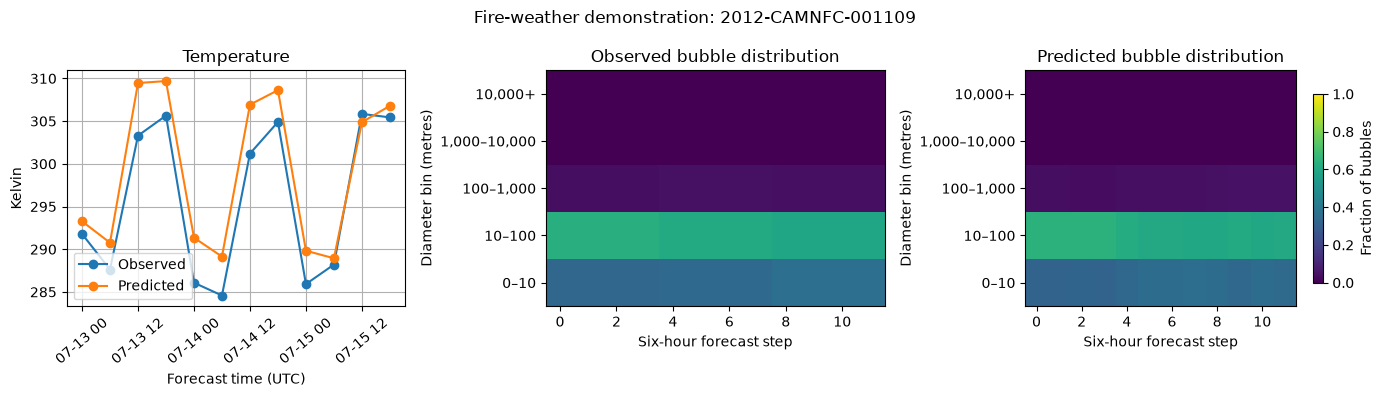

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
temperature_index = WEATHER.index("Temperature_height_above_ground")
axes[0].plot(forecast_dates, observed_weather[:, temperature_index], "o-", label="Observed")
axes[0].plot(forecast_dates, predicted_weather[:, temperature_index], "o-", label="Predicted")
axes[0].set(title="Temperature", ylabel="Kelvin", xlabel="Forecast time (UTC)")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=40)
for ax, values, title in zip(axes[1:], [observed_frequency, predicted_frequency],
                             ["Observed bubble distribution", "Predicted bubble distribution"]):
    im = ax.imshow(values.T, origin="lower", aspect="auto", vmin=0, vmax=1, cmap="viridis")
    ax.set(title=title, xlabel="Six-hour forecast step", ylabel="Diameter bin (metres)")
    ax.set_yticks(range(5), ["0–10", "10–100", "100–1,000", "1,000–10,000", "10,000+"])
    ax.grid(False)
fig.colorbar(im, ax=axes[2], label="Fraction of bubbles", shrink=0.8)
fig.suptitle(f"Fire-weather demonstration: {fire_groups[example_index]}")
fig.tight_layout()
plt.show()

## Using other data

Keep the same feature order and units. Build sequences within each site or fire. Save normalization parameters with any new weights; use the included normalization with the included weights.